# DWD-Wetteranalyse Berlin

Dieses Notebook wertet die heruntergeladene CSV-Datei `dwd_berlin_2020_bis_2026-11-01.csv` aus. Sie enthält tägliche DWD-Messungen der Station **Berlin-Dahlem (FU), 00403** vom 01.01.2020 bis zum letzten verfügbaren Tag **01.11.2026**.

Die Datei enthält 2.497 Kalendertage. Davon sind 2.481 Werte für Minimum, Maximum und Tagesmitteltemperatur, 2.482 Niederschlagswerte und 2.481 Sonnenscheindauerwerte vorhanden. Leere Felder sind fehlende DWD-Messungen und werden nicht künstlich ergänzt.

Quelle: [DWD Climate Data Center, Tageswerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/). Die CSV muss im selben Ordner wie dieses Notebook liegen.

## Übliche Schritte einer Datenanalyse

1. **Fragestellung festlegen:** Was soll untersucht oder beantwortet werden?
2. **Daten beschaffen:** Eine passende, dokumentierte Quelle auswählen und den Zeitraum sowie den räumlichen Bezug festlegen.
3. **Daten verstehen:** Spalten, Einheiten, Datentypen und Abdeckung prüfen.
4. **Daten bereinigen:** Fehlwerte, Ausreißer und uneinheitliche Formate erkennen; Änderungen nachvollziehbar dokumentieren.
5. **Daten auswerten:** Kennzahlen, Gruppierungen oder Vergleiche berechnen, die zur Fragestellung passen.
6. **Ergebnisse visualisieren:** Geeignete Diagramme mit klaren Achsen, Einheiten und Legenden erstellen.
7. **Ergebnisse interpretieren:** Muster und Unterschiede beschreiben, Unsicherheiten und Grenzen der Daten beachten.
8. **Analyse dokumentieren:** Schritte, Annahmen und Quellen festhalten, damit die Auswertung nachvollziehbar bleibt.

**In dieser Analyse:** Wir betrachten DWD-Tageswerte aus Berlin-Dahlem, prüfen ihre Vollständigkeit und untersuchen Temperatur, Niederschlag und Sonnenscheindauer.

## 1. Bibliotheken vorbereiten

Pandas liest und untersucht die CSV, Matplotlib zeichnet die Zeitreihen und scikit-learn stellt das Prognosemodell bereit. Falls eine Bibliothek fehlt, installiere sie im Terminal der Notebook-Umgebung mit:

```bash
python -m pip install pandas matplotlib scikit-learn
```

Die folgende Codezelle enthält nur reguläre Python-Imports, damit sie auch von Python-Analysewerkzeugen geprüft werden kann.

In [39]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. CSV laden

Lies die bereits heruntergeladene Tagesdatei ein. Die Datumsspalte wird als Datumsindex gesetzt, damit Pandas Zeitreihenfunktionen verwenden kann.

In [40]:
csv_datei = Path("dwd_berlin_2020_bis_2026-11-01.csv")
if not csv_datei.exists():
    raise FileNotFoundError(f"CSV nicht gefunden: {csv_datei.resolve()}")

wetter = pd.read_csv(csv_datei, parse_dates=["datum"], index_col="datum")
wetter = wetter.sort_index()

messgroessen = ["temp_min_c", "temp_max_c", "temp_mean_c", "niederschlag_mm", "sonnenstunden_h"]
assert all(spalte in wetter.columns for spalte in messgroessen)
print("Zeitraum:", wetter.index.min().date(), "bis", wetter.index.max().date())
print("Kalendertage:", len(wetter))
wetter.head()

Zeitraum: 2020-01-01 bis 2026-11-01
Kalendertage: 2497


,temp_min_c,temp_max_c,temp_mean_c,niederschlag_mm,sonnenstunden_h
datum,,,,,
2020-01-01,-2.8,5.0,1.8,0.0,2.9
2020-01-02,-4.1,6.2,-0.3,0.0,7.5
2020-01-03,0.8,6.9,4.3,4.4,0.0
2020-01-04,1.7,5.6,4.1,3.0,0.0
2020-01-05,-1.4,3.6,1.4,0.0,2.1


## 3. Datenqualität und erste Exploration

Prüfe, wie viele Werte pro Messgröße vorhanden sind. Fehlende DWD-Werte bleiben fehlend; für einfache Kennzahlen verwendet Pandas automatisch die vorhandenen Messungen.

In [41]:
abdeckung = pd.DataFrame(
    {
        "vorhanden": wetter.notna().sum(),
        "fehlend": wetter.isna().sum(),
        "abdeckung_prozent": (wetter.notna().mean() * 100).round(2),
    }
)
display(abdeckung)
display(wetter.describe().T.round(2))

,vorhanden,fehlend,abdeckung_prozent
temp_min_c,2481,16,99.36
temp_max_c,2481,16,99.36
temp_mean_c,2481,16,99.36
niederschlag_mm,2482,15,99.40
sonnenstunden_h,2481,16,99.36


,count,mean,std,min,25%,50%,75%,max
temp_min_c,2481.0,6.61,6.33,-12.2,1.7,6.7,11.9,21.4
temp_max_c,2481.0,15.65,8.74,-7.2,8.7,15.8,22.5,39.0
temp_mean_c,2481.0,11.09,7.30,-9.0,5.6,10.9,17.1,29.7
niederschlag_mm,2482.0,1.44,3.45,0.0,0.0,0.0,1.2,44.6
sonnenstunden_h,2481.0,5.63,4.66,0.0,1.0,5.1,9.5,16.1


Jede farbige Linie zeigt die tägliche Mitteltemperatur eines Jahres auf derselben Monats-/Tagesachse. Der 29. Februar wird auf einem Schaltjahr-Kalender geführt; in Nicht-Schaltjahren entsteht dort eine Lücke. 2026 reicht nur bis zum letzten verfügbaren DWD-Messtag.

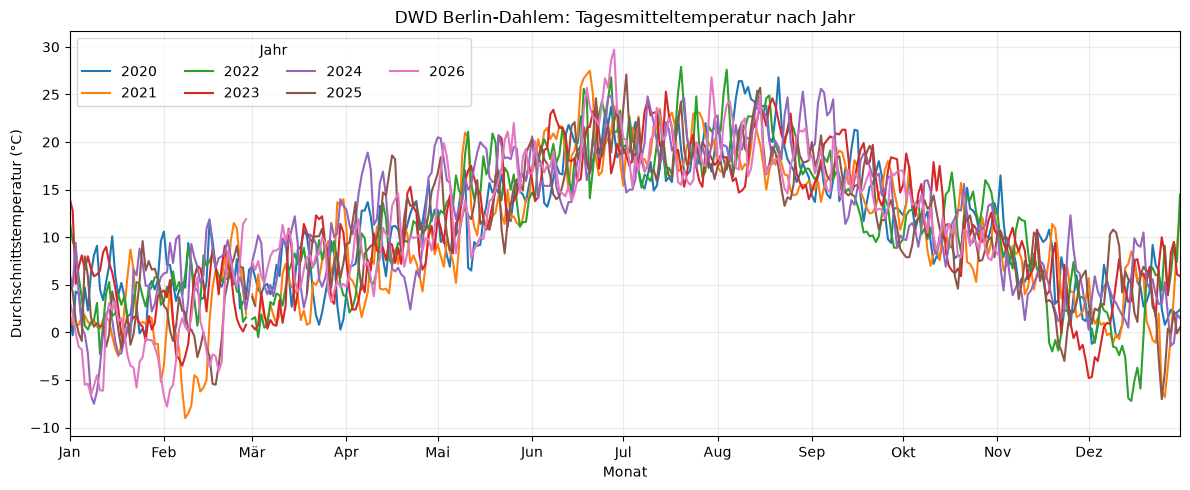

In [42]:
temperatur_jahresverlauf = wetter[["temp_mean_c"]].copy()
temperatur_jahresverlauf["jahr"] = temperatur_jahresverlauf.index.year
temperatur_jahresverlauf["kalendertag"] = pd.to_datetime(
    "2000-" + temperatur_jahresverlauf.index.strftime("%m-%d")
).day_of_year
temperatur_jahresverlauf = temperatur_jahresverlauf.pivot(
    index="kalendertag", columns="jahr", values="temp_mean_c"
)

fig, ax = plt.subplots(figsize=(12, 5))
for jahr in temperatur_jahresverlauf.columns:
    ax.plot(temperatur_jahresverlauf.index, temperatur_jahresverlauf[jahr], linewidth=1.5, label=str(jahr))

monat_ticks = pd.date_range("2000-01-01", "2000-12-01", freq="MS")
ax.set_xticks(monat_ticks.day_of_year, ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_xlim(1, 366)
ax.set_title("DWD Berlin-Dahlem: Tagesmitteltemperatur nach Jahr")
ax.set_xlabel("Monat")
ax.set_ylabel("Durchschnittstemperatur (°C)")
ax.legend(title="Jahr", ncols=4)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Bandbreite zwischen den Jahren

Die Bandbreite wird hier pro Kalendertag als höchste minus niedrigste Tagesmitteltemperatur über vollständige Jahre berechnet. Für einen fairen Vergleich verwenden wir 2020-2025 und schließen 2026 als unvollständiges Jahr aus. Ein Kalendertag wird berücksichtigt, wenn für mindestens fünf der sechs Jahre ein Messwert vorliegt. Die folgende Übersicht mittelt diese Tagesbandbreiten je Monat und vergleicht Winter (Dezember-Februar) mit Sommer (Juni-August).

Winter (Dez-Feb): 10.05 °C
Sommer (Jun-Aug): 7.15 °C
Differenz: 2.91 °C (41 % größer im Winter)


,mittlere_tagesbandbreite_c,tage_beruecksichtigt
monat,,
1,9.04,31
2,10.73,28
3,7.82,31
4,9.48,30
5,8.40,31
6,7.27,30
7,6.69,31
8,7.48,31
9,7.78,30


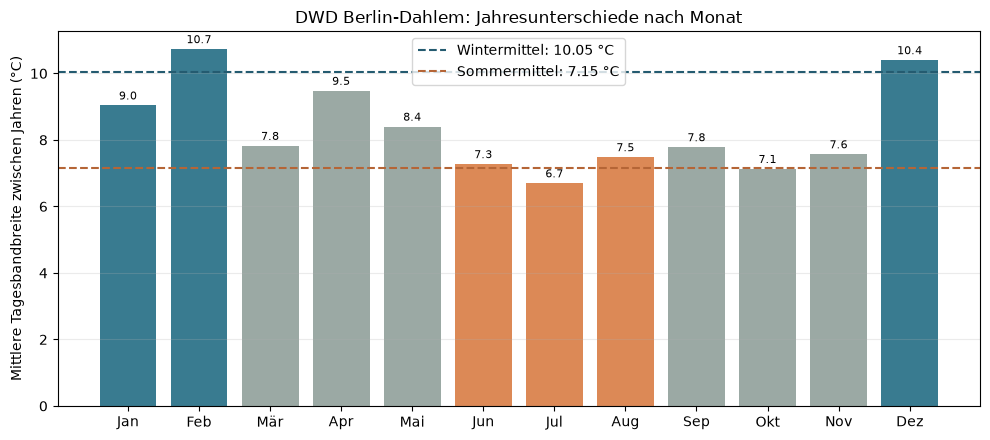

In [43]:
band_daten = wetter.loc["2020-01-01":"2025-12-31", ["temp_mean_c"]].copy()
band_daten["jahr"] = band_daten.index.year
band_daten["monat"] = band_daten.index.month
band_daten["kalendertag"] = band_daten.index.strftime("%m-%d")
band_pivot = band_daten.pivot(index=["monat", "kalendertag"], columns="jahr", values="temp_mean_c")
anzahl_jahre = band_pivot.count(axis=1)
tagesbandbreite = (band_pivot.max(axis=1) - band_pivot.min(axis=1)).where(anzahl_jahre >= 5)

monatliche_bandbreite = (
    tagesbandbreite.rename("bandbreite_c")
    .reset_index()
    .groupby("monat")["bandbreite_c"]
    .agg(["mean", "count"])
)
winter = monatliche_bandbreite.loc[[12, 1, 2], "mean"].mean()
sommer = monatliche_bandbreite.loc[[6, 7, 8], "mean"].mean()
print(f"Winter (Dez-Feb): {winter:.2f} °C")
print(f"Sommer (Jun-Aug): {sommer:.2f} °C")
print(f"Differenz: {winter - sommer:.2f} °C ({(winter / sommer - 1) * 100:.0f} % größer im Winter)")
display(monatliche_bandbreite.rename(columns={"mean": "mittlere_tagesbandbreite_c", "count": "tage_beruecksichtigt"}).round(2))

monat_namen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
farben = ["#397b90" if monat in [12, 1, 2] else "#dc8956" if monat in [6, 7, 8] else "#9ba9a4" for monat in range(1, 13)]
fig, ax = plt.subplots(figsize=(10, 4.5))
balken = ax.bar(range(1, 13), monatliche_bandbreite["mean"], color=farben)
ax.axhline(winter, color="#245b70", linestyle="--", label=f"Wintermittel: {winter:.2f} °C")
ax.axhline(sommer, color="#b56536", linestyle="--", label=f"Sommermittel: {sommer:.2f} °C")
ax.set_xticks(range(1, 13), monat_namen)
ax.set_ylabel("Mittlere Tagesbandbreite zwischen Jahren (°C)")
ax.set_title("DWD Berlin-Dahlem: Jahresunterschiede nach Monat")
ax.legend()
ax.grid(axis="y", alpha=0.25)
for balken_aktuell, wert in zip(balken, monatliche_bandbreite["mean"]):
    ax.text(balken_aktuell.get_x() + balken_aktuell.get_width() / 2, wert + 0.1, f"{wert:.1f}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

## 5. Niederschlag pro Tag

Die Säulen zeigen die gemessene Niederschlagsmenge pro Tag. Zusätzlich fassen wir die Werte zu Monatssummen zusammen, um saisonale Unterschiede sichtbar zu machen. Fehlende Messungen erscheinen als Lücken.

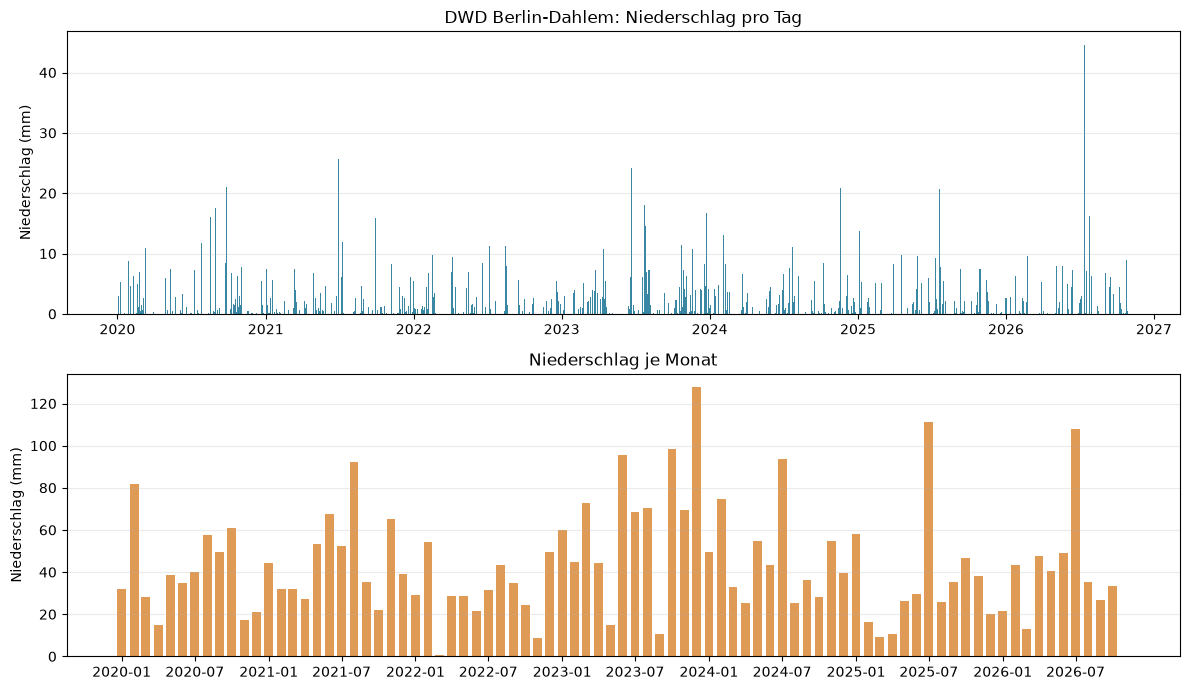

In [44]:
niederschlag_monat = wetter["niederschlag_mm"].resample("MS").sum(min_count=1)

fig, achsen = plt.subplots(2, 1, figsize=(12, 7))
achsen[0].bar(wetter.index, wetter["niederschlag_mm"], width=1.0, color="#3987a3")
achsen[0].set_title("DWD Berlin-Dahlem: Niederschlag pro Tag")
achsen[0].set_ylabel("Niederschlag (mm)")
achsen[0].grid(axis="y", alpha=0.25)

achsen[1].bar(niederschlag_monat.index, niederschlag_monat.values, width=22, color="#df9a55")
achsen[1].set_xticks(niederschlag_monat.index[::6], niederschlag_monat.index.strftime("%Y-%m")[::6])
achsen[1].set_title("Niederschlag je Monat")
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Sonnenscheindauer und Extremtage

Die tägliche Sonnenscheindauer wird mit einem 30-Tage-Mittel dargestellt. Zum Abschluss ermitteln wir die kälteste Mindesttemperatur, höchste Höchsttemperatur, das größte Tagesmittel, den stärksten Tagesniederschlag und die meisten Sonnenstunden. Fehlwerte werden bei diesen Berechnungen übersprungen.

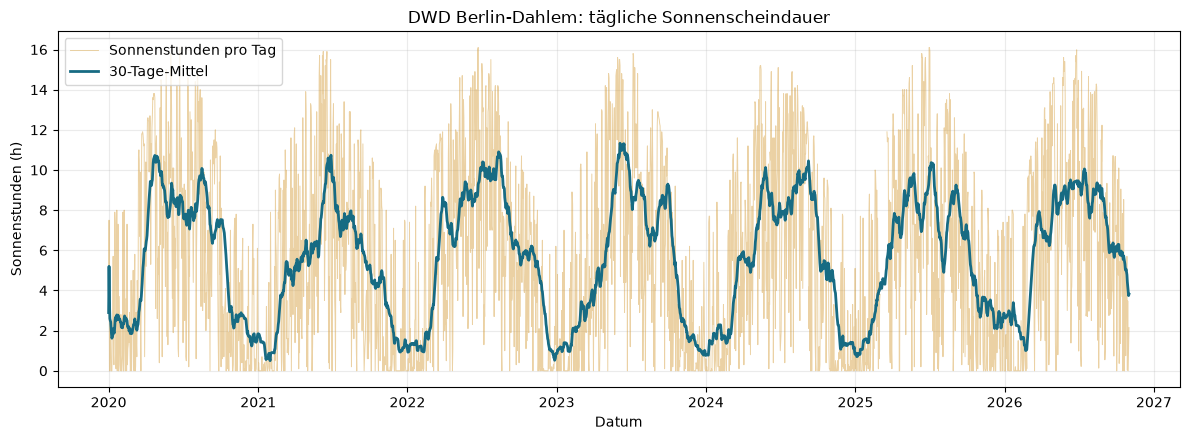

,Ereignis,Datum,Messwert
0,Kältester Tag (Tagesminimum),2021-02-10,-12.2 °C
1,Wärmster Tag (Tagesmaximum),2026-06-27,39.0 °C
2,Höchstes Tagesmittel,2026-06-28,29.7 °C
3,Stärkster Tagesniederschlag,2026-07-14,44.6 mm
4,Meiste Sonnenstunden,2020-06-23,16.1 h


In [45]:
sonnen_30_tage = wetter["sonnenstunden_h"].rolling(30, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(wetter.index, wetter["sonnenstunden_h"], color="#d39b35", linewidth=0.7, alpha=0.45, label="Sonnenstunden pro Tag")
ax.plot(wetter.index, sonnen_30_tage, color="#176b83", linewidth=2, label="30-Tage-Mittel")
ax.set_title("DWD Berlin-Dahlem: tägliche Sonnenscheindauer")
ax.set_xlabel("Datum")
ax.set_ylabel("Sonnenstunden (h)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

extremwerte = pd.DataFrame(
    [
        {"Ereignis": "Kältester Tag (Tagesminimum)", "Datum": wetter["temp_min_c"].idxmin(), "Messwert": f"{wetter['temp_min_c'].min():.1f} °C"},
        {"Ereignis": "Wärmster Tag (Tagesmaximum)", "Datum": wetter["temp_max_c"].idxmax(), "Messwert": f"{wetter['temp_max_c'].max():.1f} °C"},
        {"Ereignis": "Höchstes Tagesmittel", "Datum": wetter["temp_mean_c"].idxmax(), "Messwert": f"{wetter['temp_mean_c'].max():.1f} °C"},
        {"Ereignis": "Stärkster Tagesniederschlag", "Datum": wetter["niederschlag_mm"].idxmax(), "Messwert": f"{wetter['niederschlag_mm'].max():.1f} mm"},
        {"Ereignis": "Meiste Sonnenstunden", "Datum": wetter["sonnenstunden_h"].idxmax(), "Messwert": f"{wetter['sonnenstunden_h'].max():.1f} h"},
    ]
)
display(extremwerte)

# Datenprognose mit KI


## 7. Prognose der Tagesmitteltemperatur mit einem KI-Modell

Wir sagen die Tagesmitteltemperatur für einen Tag voraus. Als Eingaben dienen die Tagesmittel der fünf unmittelbar vorhergehenden Tage sowie der Kalendertag im Jahr (1 bis 365). Das Modell gibt genau einen Tag voraus; für die Testphase werden die tatsächlichen Messungen der vorangegangenen Tage verwendet.

Wir verwenden einen **Random Forest Regressor**. Er kombiniert viele Entscheidungsbäume und kann nichtlineare Zusammenhänge abbilden. Die Daten werden chronologisch getrennt: 2020-2024 zum Trainieren, 2025 zum Testen. So fließen keine späteren Messwerte in das Training ein. 2026 bleibt zunächst außen vor und wird erst für die abschließende Prognose verwendet.

Der 29. Februar wird als Prognoseziel ausgelassen, damit der Saison-Eingabewert immer im Bereich 1-365 liegt. Für Tage nach dem 29. Februar eines Schaltjahres wird die Tagesnummer um eins korrigiert.

### 7.1 Trainingsdaten aufbauen

Jede Zeile entspricht einem Prognosetag. `temp_vortag_1` ist der Messwert vom Vortag, `temp_vortag_5` der Messwert von fünf Tagen davor. `tag_im_jahr` beschreibt die saisonale Lage des Prognosetags. Zielwert ist `temp_mean_c` genau dieses Tages. Zeilen mit fehlenden Ziel- oder Eingabewerten werden entfernt; dadurch lernt das Modell nicht mit erfundenen Daten.

In [46]:
temperatur = wetter["temp_mean_c"].sort_index()
trainingsdaten = pd.DataFrame(index=temperatur.index)
for verzug in range(1, 6):
    trainingsdaten[f"temp_vortag_{verzug}"] = temperatur.shift(verzug)

indizes = trainingsdaten.index
schaltjahr_nach_februar = indizes.is_leap_year & (indizes.month > 2)
trainingsdaten["tag_im_jahr"] = indizes.day_of_year - schaltjahr_nach_februar.astype(int)
trainingsdaten["ziel_temp_mean_c"] = temperatur

ist_schaltag = (indizes.month == 2) & (indizes.day == 29)
trainingsdaten = trainingsdaten.loc[~ist_schaltag].dropna()
eingangsspalten = [f"temp_vortag_{verzug}" for verzug in range(1, 6)] + ["tag_im_jahr"]

print("Verwendbare Trainingsbeispiele:", len(trainingsdaten))
print("Eingabespalten:", eingangsspalten)
print("Bereich der Tag-im-Jahr-Eingabe:", trainingsdaten["tag_im_jahr"].min(), "bis", trainingsdaten["tag_im_jahr"].max())
display(trainingsdaten.head())

Verwendbare Trainingsbeispiele: 2469
Eingabespalten: ['temp_vortag_1', 'temp_vortag_2', 'temp_vortag_3', 'temp_vortag_4', 'temp_vortag_5', 'tag_im_jahr']
Bereich der Tag-im-Jahr-Eingabe: 1 bis 365


,temp_vortag_1,temp_vortag_2,temp_vortag_3,temp_vortag_4,temp_vortag_5,tag_im_jahr,ziel_temp_mean_c
datum,,,,,,,
2020-01-06,1.4,4.1,4.3,-0.3,1.8,6,4.7
2020-01-07,4.7,1.4,4.1,4.3,-0.3,7,2.3
2020-01-08,2.3,4.7,1.4,4.1,4.3,8,6.2
2020-01-09,6.2,2.3,4.7,1.4,4.1,9,8.1
2020-01-10,8.1,6.2,2.3,4.7,1.4,10,9.1


### 7.2 Trainings- und Testdaten trennen

Wir trainieren mit Prognosetagen vor dem 01.01.2025 und testen ausschließlich auf dem Kalenderjahr 2025. Dieser zeitliche Split ist für Zeitreihen realistischer als eine zufällige Aufteilung: Das Modell sieht beim Training keine zukünftigen Jahre. Die tatsächlichen Vorwerte innerhalb des Testjahres stehen jeweils zur Verfügung, wie bei einer täglichen Ein-Tages-Prognose.

In [47]:
train_daten = trainingsdaten.loc[trainingsdaten.index < "2025-01-01"]
test_daten = trainingsdaten.loc[
    (trainingsdaten.index >= "2025-01-01") & (trainingsdaten.index < "2026-01-01")
]

x_train = train_daten[eingangsspalten]
y_train = train_daten["ziel_temp_mean_c"]
x_test = test_daten[ eingangsspalten]
y_test = test_daten["ziel_temp_mean_c"]

assert len(train_daten) > 0 and len(test_daten) > 0
print(f"Training: {train_daten.index.min().date()} bis {train_daten.index.max().date()} ({len(train_daten)} Beispiele)")
print(f"Test: {test_daten.index.min().date()} bis {test_daten.index.max().date()} ({len(test_daten)} Beispiele)")
display(x_train.head())

Training: 2020-01-06 bis 2024-12-31 (1820 Beispiele)
Test: 2025-01-01 bis 2025-12-31 (344 Beispiele)


,temp_vortag_1,temp_vortag_2,temp_vortag_3,temp_vortag_4,temp_vortag_5,tag_im_jahr
datum,,,,,,
2020-01-06,1.4,4.1,4.3,-0.3,1.8,6
2020-01-07,4.7,1.4,4.1,4.3,-0.3,7
2020-01-08,2.3,4.7,1.4,4.1,4.3,8
2020-01-09,6.2,2.3,4.7,1.4,4.1,9
2020-01-10,8.1,6.2,2.3,4.7,1.4,10


### 7.3 Modell trainieren

Der Random Forest lernt aus den sechs Eingaben die Zieltemperatur. Eine Skalierung ist für baumbasierte Modelle nicht erforderlich. Der feste Zufallsstartwert macht den Lauf reproduzierbar; begrenzte Baumtiefe und Mindestblattgröße helfen, Überanpassung zu reduzieren.

In [48]:
modell = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell.fit(x_train, y_train)
vorhersage_test = pd.Series(modell.predict(x_test), index=x_test.index, name="prognose_c")

print("Modell trainiert.")
print("Anzahl Bäume:", modell.n_estimators)
print("Eingabemerkmale:", list(x_train.columns))

Modell trainiert.
Anzahl Bäume: 300
Eingabemerkmale: ['temp_vortag_1', 'temp_vortag_2', 'temp_vortag_3', 'temp_vortag_4', 'temp_vortag_5', 'tag_im_jahr']


### 7.4 Genauigkeit auf dem Testjahr prüfen

Wir messen die Fehler auf den nicht zum Training verwendeten Testtagen 2025. Der **MAE** ist der durchschnittliche absolute Fehler in °C; der **RMSE** gewichtet größere Fehler stärker. **R²** beschreibt, wie viel der Temperaturschwankung das Modell erklärt. Als Referenz dient eine Persistence-Baseline: Sie sagt für morgen den Wert von heute voraus.

,MAE (°C),RMSE (°C),R²
Random Forest,1.67,2.12,0.91
Vortag-Baseline,1.76,2.26,0.90


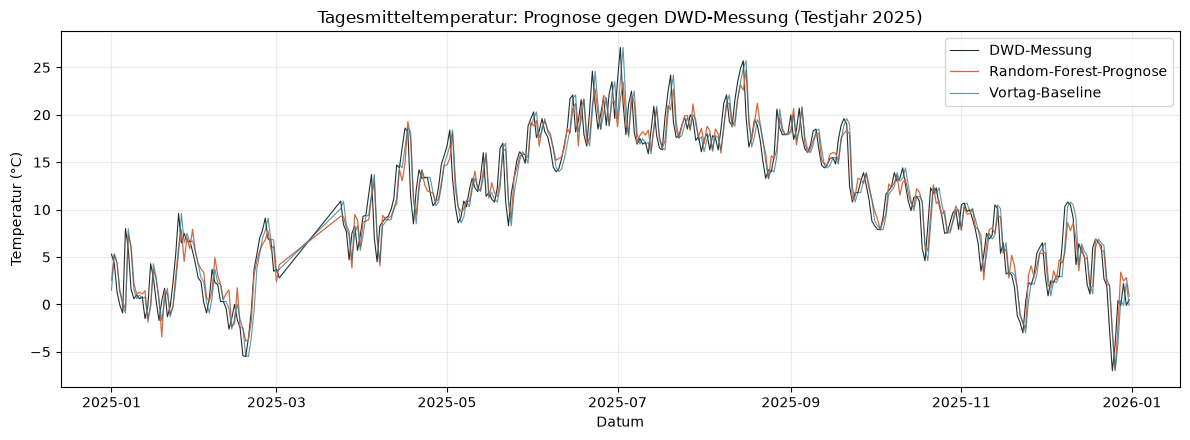

In [49]:
baseline_test = x_test["temp_vortag_1"]
test_ergebnisse = pd.DataFrame(
    {
        "MAE (°C)": [
            mean_absolute_error(y_test, vorhersage_test),
            mean_absolute_error(y_test, baseline_test),
        ],
        "RMSE (°C)": [
            mean_squared_error(y_test, vorhersage_test) ** 0.5,
            mean_squared_error(y_test, baseline_test) ** 0.5,
        ],
        "R²": [r2_score(y_test, vorhersage_test), r2_score(y_test, baseline_test)],
    },
    index=["Random Forest", "Vortag-Baseline"],
)
display(test_ergebnisse.round(2))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y_test.index, y_test, color="#242f33", linewidth=0.8, label="DWD-Messung")
ax.plot(vorhersage_test.index, vorhersage_test, color="#d16a42", linewidth=0.9, label="Random-Forest-Prognose")
ax.plot(baseline_test.index, baseline_test, color="#176b83", linewidth=0.8, alpha=0.7, label="Vortag-Baseline")
ax.set_title("Tagesmitteltemperatur: Prognose gegen DWD-Messung (Testjahr 2025)")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### 7.5 Prognose für den nächsten Tag

Nach der unabhängigen Bewertung trainieren wir ein finales Modell mit allen gültigen Beispielen bis zum letzten DWD-Messtag. Für die Prognose verwenden wir die fünf letzten aufeinanderfolgenden Messwerte und den Kalendertag des Folgetags. Das Ergebnis ist ein einzelner Schätzwert ohne Prognoseintervall; Wetter hängt auch von Faktoren ab, die dieses einfache Modell nicht kennt.

In [50]:
letzter_messwert = temperatur.dropna().index.max()
prognose_datum = letzter_messwert + pd.Timedelta(days=1)
letzte_fuenf_daten = pd.date_range(end=letzter_messwert, periods=5, freq="D")
letzte_fuenf_temperaturen = temperatur.reindex(letzte_fuenf_daten)

if letzte_fuenf_temperaturen.isna().any():
    raise ValueError("Für die Prognose fehlen zusammenhängende Temperaturwerte der letzten fünf Tage.")

tag_im_jahr_prognose = prognose_datum.day_of_year
if prognose_datum.is_leap_year and prognose_datum.month > 2:
    tag_im_jahr_prognose -= 1

prognose_eingabe = {
    f"temp_vortag_{verzug}": [letzte_fuenf_temperaturen.iloc[-verzug]]
    for verzug in range(1, 6)
}
prognose_eingabe["tag_im_jahr"] = [tag_im_jahr_prognose]
x_prognose = pd.DataFrame(prognose_eingabe, columns=eingangsspalten)

modell_final = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell_final.fit(trainingsdaten[ eingangsspalten], trainingsdaten["ziel_temp_mean_c"])
temperatur_prognose = modell_final.predict(x_prognose)[0]

print("Letzter Messwert:", letzter_messwert.date())
print("Prognosedatum:", prognose_datum.date())
print(f"Prognostizierte Tagesmitteltemperatur: {temperatur_prognose:.1f} °C")
display(x_prognose)

Letzter Messwert: 2026-11-01
Prognosedatum: 2026-11-02
Prognostizierte Tagesmitteltemperatur: 8.9 °C


,temp_vortag_1,temp_vortag_2,temp_vortag_3,temp_vortag_4,temp_vortag_5,tag_im_jahr
0,8.2,9.0,7.6,7.8,8.8,306


## 8. Vergleichsmodell mit allen Wettergrößen

Das zweite Modell verwendet für jeden der fünf Vortage Tagesminimum, Tagesmaximum, Tagesmitteltemperatur, Sonnenscheindauer und Niederschlag. Zusätzlich bleibt der Kalendertag als saisonales Merkmal erhalten. Modelltyp und Parameter sind identisch zum ersten Random Forest.

Die Eingabefenster mit fehlenden Messwerten werden nicht aufgefüllt, sondern ausgeschlossen. Für den Leistungsvergleich werten wir beide Modelle und die Vortag-Baseline ausschließlich auf den gemeinsamen vollständigen Testtagen 2025 aus. Damit sind die Kennzahlen direkt vergleichbar.

In [51]:
wetter_merkmale = [
    "temp_min_c",
    "temp_max_c",
    "temp_mean_c",
    "sonnenstunden_h",
    "niederschlag_mm",
]
trainingsdaten_wetter = pd.DataFrame(index=wetter.index)
for merkmal in wetter_merkmale:
    for verzug in range(1, 6):
        trainingsdaten_wetter[f"{merkmal}_vortag_{verzug}"] = wetter[merkmal].shift(verzug)

indizes_wetter = trainingsdaten_wetter.index
schaltjahr_nach_februar_wetter = indizes_wetter.is_leap_year & (indizes_wetter.month > 2)
trainingsdaten_wetter["tag_im_jahr"] = indizes_wetter.day_of_year - schaltjahr_nach_februar_wetter.astype(int)
trainingsdaten_wetter["ziel_temp_mean_c"] = wetter["temp_mean_c"]

ist_schaltag_wetter = (indizes_wetter.month == 2) & (indizes_wetter.day == 29)
trainingsdaten_wetter = trainingsdaten_wetter.loc[~ist_schaltag_wetter].dropna()
eingangsspalten_wetter = [
    f"{merkmal}_vortag_{verzug}"
    for merkmal in wetter_merkmale
    for verzug in range(1, 6)
] + ["tag_im_jahr"]

train_daten_wetter = trainingsdaten_wetter.loc[trainingsdaten_wetter.index < "2025-01-01"]
test_daten_wetter = trainingsdaten_wetter.loc[
    (trainingsdaten_wetter.index >= "2025-01-01")
    & (trainingsdaten_wetter.index < "2026-01-01")
]
tage_vergleich = test_daten_wetter.index.intersection(test_daten.index)

print("Eingabemerkmale:", len(eingangsspalten_wetter))
print("Trainingsbeispiele mit vollständigen Wetterdaten:", len(train_daten_wetter))
print("Gemeinsame Testtage 2025 für beide Modelle:", len(tage_vergleich))
display(trainingsdaten_wetter.head())

Eingabemerkmale: 26
Trainingsbeispiele mit vollständigen Wetterdaten: 1820
Gemeinsame Testtage 2025 für beide Modelle: 344


,temp_min_c_vortag_1,temp_min_c_vortag_2,temp_min_c_vortag_3,temp_min_c_vortag_4,temp_min_c_vortag_5,temp_max_c_vortag_1,temp_max_c_vortag_2,temp_max_c_vortag_3,temp_max_c_vortag_4,temp_max_c_vortag_5,...,sonnenstunden_h_vortag_3,sonnenstunden_h_vortag_4,sonnenstunden_h_vortag_5,niederschlag_mm_vortag_1,niederschlag_mm_vortag_2,niederschlag_mm_vortag_3,niederschlag_mm_vortag_4,niederschlag_mm_vortag_5,tag_im_jahr,ziel_temp_mean_c
datum,,,,,,,,,,,,,,,,,,,,,
2020-01-06,-1.4,1.7,0.8,-4.1,-2.8,3.6,5.6,6.9,6.2,5.0,...,0.0,7.5,2.9,0.0,3.0,4.4,0.0,0.0,6,4.7
2020-01-07,1.9,-1.4,1.7,0.8,-4.1,7.3,3.6,5.6,6.9,6.2,...,0.0,0.0,7.5,0.0,0.0,3.0,4.4,0.0,7,2.3
2020-01-08,-2.1,1.9,-1.4,1.7,0.8,5.3,7.3,3.6,5.6,6.9,...,2.1,0.0,0.0,0.2,0.0,0.0,3.0,4.4,8,6.2
2020-01-09,3.1,-2.1,1.9,-1.4,1.7,8.2,5.3,7.3,3.6,5.6,...,2.1,2.1,0.0,1.9,0.2,0.0,0.0,3.0,9,8.1
2020-01-10,7.0,3.1,-2.1,1.9,-1.4,9.7,8.2,5.3,7.3,3.6,...,0.0,2.1,2.1,5.3,1.9,0.2,0.0,0.0,10,9.1


### 8.1 Zweites Modell trainieren und fair vergleichen

Das zweite Modell erhält dieselben Random-Forest-Einstellungen wie das erste. Für den Vergleich werden beide Random Forests und die Vortag-Baseline auf genau denselben vollständigen Testtagen 2025 bewertet. So beeinflussen fehlende Sonnen- oder Niederschlagswerte den Vergleich nicht durch unterschiedliche Testzeiträume.

In [52]:
x_train_wetter = train_daten_wetter[eingangsspalten_wetter]
y_train_wetter = train_daten_wetter["ziel_temp_mean_c"]
x_test_wetter = test_daten_wetter.loc[tage_vergleich, eingangsspalten_wetter]
y_test_vergleich = y_test.reindex(tage_vergleich)

modell_wetter = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell_wetter.fit(x_train_wetter, y_train_wetter)
vorhersage_wetter_test = pd.Series(
    modell_wetter.predict(x_test_wetter),
    index=tage_vergleich,
    name="prognose_alle_wettergroessen_c",
)

vorhersagen_vergleich = {
    "RF: Tagesmittel der letzten 5 Tage": vorhersage_test.reindex(tage_vergleich),
    "RF: alle Wettergrößen der letzten 5 Tage": vorhersage_wetter_test,
    "Vortag-Baseline": x_test.loc[tage_vergleich, "temp_vortag_1"],
}
vergleichsmetriken = pd.DataFrame(
    {
        "MAE (°C)": {
            name: mean_absolute_error(y_test_vergleich, vorhersage)
            for name, vorhersage in vorhersagen_vergleich.items()
        },
        "RMSE (°C)": {
            name: mean_squared_error(y_test_vergleich, vorhersage) ** 0.5
            for name, vorhersage in vorhersagen_vergleich.items()
        },
        "R²": {
            name: r2_score(y_test_vergleich, vorhersage)
            for name, vorhersage in vorhersagen_vergleich.items()
        },
    }
)

print("Gemeinsame Testtage:", len(tage_vergleich))
display(vergleichsmetriken.round(2))

Gemeinsame Testtage: 344


,MAE (°C),RMSE (°C),R²
RF: Tagesmittel der letzten 5 Tage,1.67,2.12,0.91
RF: alle Wettergrößen der letzten 5 Tage,1.58,2.02,0.92
Vortag-Baseline,1.76,2.26,0.90


### 8.2 Prognose für den nächsten Tag mit allen Wettergrößen

Für die zweite Prognose werden die letzten fünf aufeinanderfolgenden DWD-Tage benötigt. Das finale Modell wird wie zuvor mit allen verfügbaren Trainingsbeispielen trainiert. Die Tabelle stellt beide Ein-Tages-Schätzungen gegenüber.

In [54]:
letzte_fuenf_wetterdaten = wetter.reindex(letzte_fuenf_daten)[wetter_merkmale]
if letzte_fuenf_wetterdaten.isna().any().any():
    raise ValueError("Für das Vergleichsmodell fehlen Messwerte in den letzten fünf Tagen.")

modell_wetter_final = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell_wetter_final.fit(
    trainingsdaten_wetter[eingangsspalten_wetter],
    trainingsdaten_wetter["ziel_temp_mean_c"],
)

prognose_wetter_eingabe = {}
for merkmal in wetter_merkmale:
    for verzug in range(1, 6):
        prognose_wetter_eingabe[f"{merkmal}_vortag_{verzug}"] = [
            letzte_fuenf_wetterdaten[merkmal].iloc[-verzug]
        ]
prognose_wetter_eingabe["tag_im_jahr"] = [tag_im_jahr_prognose]
x_prognose_wetter = pd.DataFrame(
    prognose_wetter_eingabe,
    columns=eingangsspalten_wetter,
)
temperatur_prognose_wetter = modell_wetter_final.predict(x_prognose_wetter)[0]

prognose_vergleich = pd.DataFrame(
    {
        "Prognosedatum": [prognose_datum, prognose_datum],
        "Tagesmitteltemperatur (°C)": [temperatur_prognose, temperatur_prognose_wetter],
    },
    index=["RF: letzte 5 Tagesmittel", "RF: alle Wettergrößen der letzten 5 Tage"],
)
prognose_vergleich["Tagesmitteltemperatur (°C)"] = prognose_vergleich["Tagesmitteltemperatur (°C)"].round(1)
display(prognose_vergleich)

,Prognosedatum,Tagesmitteltemperatur (°C)
RF: letzte 5 Tagesmittel,2026-11-02,8.9
RF: alle Wettergrößen der letzten 5 Tage,2026-11-02,8.2
